GPU INFERENCE AND BOTTLENECK ANALYSIS
PyTorch Version: 2.14.1+cu130
Selected Device: cuda
GPU: Tesla T4

CNN model created successfully.
Input tensor shape: torch.Size([32, 3, 128, 128])

PERFORMANCE RESULTS


,Batch Size,CPU Time (ms),GPU Time (ms),Transfer Time (ms),CPU Throughput,GPU Throughput,GPU Memory (MB)
0,1,23.541,0.355,1.919,42.479,2815.379,12.674
1,4,43.098,1.030,0.432,92.812,3884.268,25.237
2,8,120.256,1.944,0.606,66.525,4115.291,44.112
3,16,212.038,3.302,1.613,75.458,4845.560,75.487
4,32,522.544,6.436,2.551,61.239,4971.801,142.487


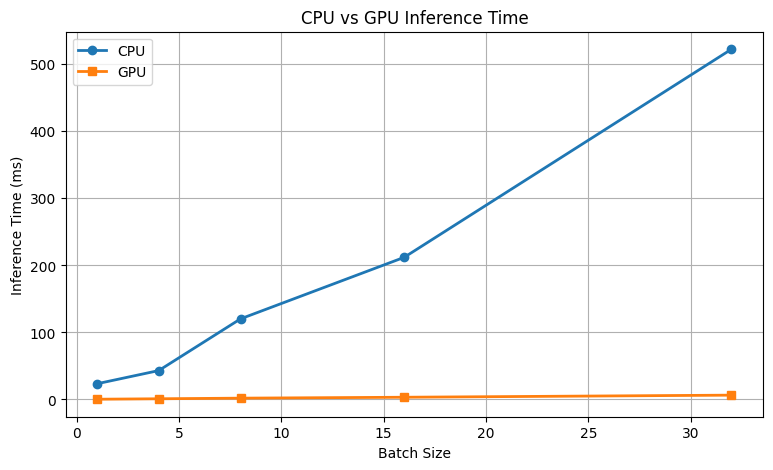

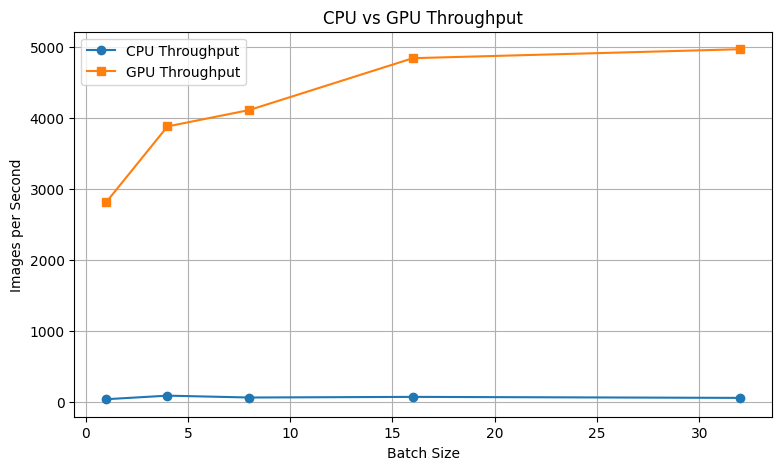

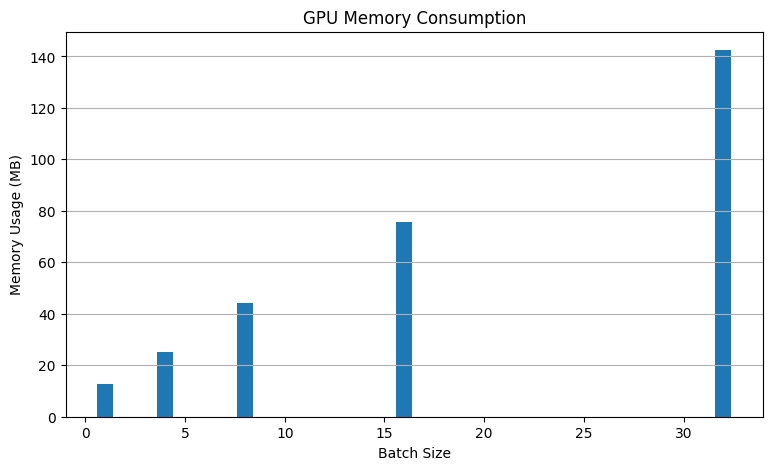

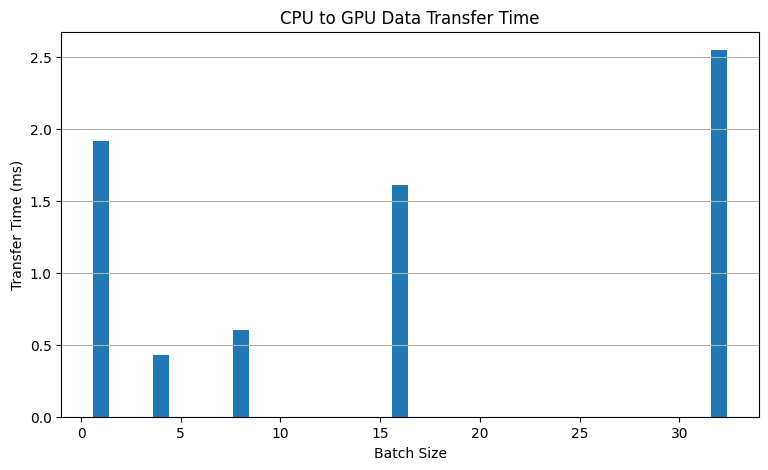

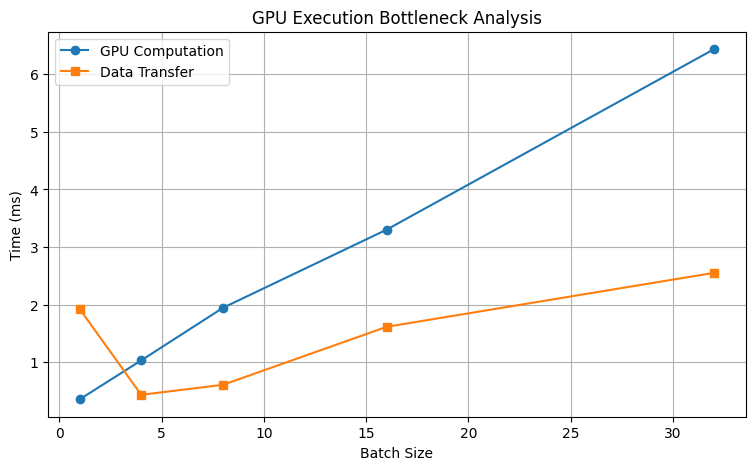


SYSTEM-LEVEL BOTTLENECK IDENTIFICATION
Average CPU Inference: 184.296 ms
Average GPU Inference: 2.613 ms
Average Data Transfer: 1.424 ms
Average GPU Memory: 60.0 MB

BOTTLENECK RESULT:
GPU computation takes more time than data transfer.
Measured GPU Speedup: 70.52 x
GPU is faster for this tested workload.

FINAL INFERENCE OUTPUT
Input Shape: (1, 3, 128, 128)
Output Shape: (1, 10)
Predicted Class: 8

EXPERIMENT COMPLETED SUCCESSFULLY!


In [1]:

# EXPERIMENT:
# GPU Inference Execution Path and System-Level Bottleneck Identification

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from IPython.display import display

# 1. DEVICE CONFIGURATION
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 65)
print("GPU INFERENCE AND BOTTLENECK ANALYSIS")
print("=" * 65)
print("PyTorch Version:", torch.__version__)
print("Selected Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. CPU benchmark will run.")

# 2. CREATE CNN MODEL
class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)

torch.manual_seed(42)
cpu_model = CNNModel().eval()
gpu_model = CNNModel().eval()
gpu_model.load_state_dict(cpu_model.state_dict())
gpu_model = gpu_model.to(device)

print("\nCNN model created successfully.")

# 3. GENERATE SAMPLE INPUT IMAGES
IMAGE_SIZE = 128
sample_images = torch.randn(32, 3, IMAGE_SIZE, IMAGE_SIZE)

print("Input tensor shape:", sample_images.shape)

# 4. INFERENCE PERFORMANCE TESTING
batch_sizes = [1, 4, 8, 16, 32]
results = []

for batch in batch_sizes:

    x_cpu = sample_images[:batch]

    # CPU benchmark
    with torch.inference_mode():
        for _ in range(5):
            cpu_model(x_cpu)

        start = time.perf_counter()

        for _ in range(20):
            cpu_model(x_cpu)

        cpu_time = (time.perf_counter() - start) / 20

    cpu_throughput = batch / cpu_time

    gpu_time = 0
    transfer_time = 0
    gpu_throughput = 0
    gpu_memory = 0

    if torch.cuda.is_available():

        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        # Measure CPU to GPU transfer
        start = time.perf_counter()
        x_gpu = x_cpu.to(device)
        torch.cuda.synchronize()
        transfer_time = time.perf_counter() - start

        # Warm-up
        with torch.inference_mode():
            for _ in range(5):
                gpu_model(x_gpu)

        torch.cuda.synchronize()

        # Measure GPU inference with CUDA events
        start_event = torch.cuda.Event(enable_timing=True)
        end_event = torch.cuda.Event(enable_timing=True)

        with torch.inference_mode():
            start_event.record()

            for _ in range(20):
                gpu_model(x_gpu)

            end_event.record()

        torch.cuda.synchronize()
        gpu_time = start_event.elapsed_time(end_event) / 1000 / 20

        gpu_throughput = batch / gpu_time
        gpu_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)

    results.append({
        "Batch Size": batch,
        "CPU Time (ms)": cpu_time * 1000,
        "GPU Time (ms)": gpu_time * 1000,
        "Transfer Time (ms)": transfer_time * 1000,
        "CPU Throughput": cpu_throughput,
        "GPU Throughput": gpu_throughput,
        "GPU Memory (MB)": gpu_memory
    })

# 5. DISPLAY RESULTS TABLE
df = pd.DataFrame(results)

print("\nPERFORMANCE RESULTS")
display(df.round(3))

# 6. GRAPH 1: CPU VS GPU INFERENCE TIME
plt.figure(figsize=(9, 5))
plt.plot(df["Batch Size"], df["CPU Time (ms)"],
         marker="o", linewidth=2, label="CPU")
if torch.cuda.is_available():
    plt.plot(df["Batch Size"], df["GPU Time (ms)"],
             marker="s", linewidth=2, label="GPU")

plt.title("CPU vs GPU Inference Time")
plt.xlabel("Batch Size")
plt.ylabel("Inference Time (ms)")
plt.legend()
plt.grid(True)
plt.show()

# 7. GRAPH 2: THROUGHPUT COMPARISON
plt.figure(figsize=(9, 5))
plt.plot(df["Batch Size"], df["CPU Throughput"],
         marker="o", label="CPU Throughput")

if torch.cuda.is_available():
    plt.plot(df["Batch Size"], df["GPU Throughput"],
             marker="s", label="GPU Throughput")

plt.title("CPU vs GPU Throughput")
plt.xlabel("Batch Size")
plt.ylabel("Images per Second")
plt.legend()
plt.grid(True)
plt.show()

# 8. GRAPH 3: GPU MEMORY USAGE
if torch.cuda.is_available():
    plt.figure(figsize=(9, 5))
    plt.bar(df["Batch Size"], df["GPU Memory (MB)"])
    plt.title("GPU Memory Consumption")
    plt.xlabel("Batch Size")
    plt.ylabel("Memory Usage (MB)")
    plt.grid(axis="y")
    plt.show()

# 9. GRAPH 4: GPU DATA TRANSFER TIME
if torch.cuda.is_available():
    plt.figure(figsize=(9, 5))
    plt.bar(df["Batch Size"], df["Transfer Time (ms)"])
    plt.title("CPU to GPU Data Transfer Time")
    plt.xlabel("Batch Size")
    plt.ylabel("Transfer Time (ms)")
    plt.grid(axis="y")
    plt.show()

# 10. GRAPH 5: BOTTLENECK COMPARISON
if torch.cuda.is_available():
    plt.figure(figsize=(9, 5))
    plt.plot(df["Batch Size"], df["GPU Time (ms)"],
             marker="o", label="GPU Computation")
    plt.plot(df["Batch Size"], df["Transfer Time (ms)"],
             marker="s", label="Data Transfer")

    plt.title("GPU Execution Bottleneck Analysis")
    plt.xlabel("Batch Size")
    plt.ylabel("Time (ms)")
    plt.legend()
    plt.grid(True)
    plt.show()

# 11. SYSTEM-LEVEL ANALYSIS
print("\n" + "=" * 65)
print("SYSTEM-LEVEL BOTTLENECK IDENTIFICATION")
print("=" * 65)

if torch.cuda.is_available():

    avg_gpu = df["GPU Time (ms)"].mean()
    avg_transfer = df["Transfer Time (ms)"].mean()
    avg_cpu = df["CPU Time (ms)"].mean()

    print("Average CPU Inference:", round(avg_cpu, 3), "ms")
    print("Average GPU Inference:", round(avg_gpu, 3), "ms")
    print("Average Data Transfer:", round(avg_transfer, 3), "ms")

    print("Average GPU Memory:",
          round(df["GPU Memory (MB)"].mean(), 2), "MB")

    print("\nBOTTLENECK RESULT:")

    if avg_transfer > avg_gpu:
        print("Data transfer overhead is higher than GPU computation.")
    else:
        print("GPU computation takes more time than data transfer.")

    speedup = avg_cpu / avg_gpu if avg_gpu > 0 else 0
    print("Measured GPU Speedup:", round(speedup, 2), "x")

    if speedup > 1:
        print("GPU is faster for this tested workload.")
    else:
        print("CPU is faster for this tested workload.")

else:
    print("GPU-specific bottleneck analysis unavailable.")

# 12. FINAL MODEL PREDICTION
with torch.inference_mode():
    test_input = sample_images[:1].to(device)
    prediction = gpu_model(test_input)
    predicted_class = torch.argmax(prediction, dim=1).item()

print("\nFINAL INFERENCE OUTPUT")
print("Input Shape:", tuple(test_input.shape))
print("Output Shape:", tuple(prediction.shape))
print("Predicted Class:", predicted_class)

print("\nEXPERIMENT COMPLETED SUCCESSFULLY!")
